**Activity 1 — Pakistani Provinces Analysis**

**Tasks covered:** dataset creation, missing-value handling, label + one-hot encoding, annotated scatter plot, and IQR outlier detection.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

provinces = pd.DataFrame({
    "Province": ["Punjab", "Sindh", "Khyber Pakhtunkhwa", "Balochistan"],
    "Population": [127.69, 55.70, 40.86, 14.89],
    "Literacy_Rate": [64.7, 57.5, 55.1, 54.0],
    "Region": ["East", "South", "North", "West"]
})

print(provinces)

             Province  Population  Literacy_Rate Region
0              Punjab      127.69           64.7   East
1               Sindh       55.70           57.5  South
2  Khyber Pakhtunkhwa       40.86           55.1  North
3         Balochistan       14.89           54.0   West


In [2]:
# Artificially introduce two missing values for demonstration.
provinces.loc[1, "Literacy_Rate"] = np.nan
provinces.loc[2, "Population"] = np.nan

# Drop one row, then fill the remaining population value with the median.
provinces_clean = provinces.drop(index=3).reset_index(drop=True)
provinces_clean["Population"] = provinces_clean["Population"].fillna(
    provinces_clean["Population"].median()
)

print(provinces_clean)

             Province  Population  Literacy_Rate Region
0              Punjab     127.690           64.7   East
1               Sindh      55.700            NaN  South
2  Khyber Pakhtunkhwa      91.695           55.1  North


In [3]:
region_map = {"North": 0, "South": 1, "East": 2, "West": 3}
provinces_clean["Region_Label"] = provinces_clean["Region"].map(region_map)

region_one_hot = pd.get_dummies(
    provinces_clean["Region"], prefix="Region", dtype=int
)

provinces_encoded = pd.concat([provinces_clean, region_one_hot], axis=1)
print(provinces_encoded)

             Province  Population  Literacy_Rate Region  Region_Label  \
0              Punjab     127.690           64.7   East             2   
1               Sindh      55.700            NaN  South             1   
2  Khyber Pakhtunkhwa      91.695           55.1  North             0   

   Region_East  Region_North  Region_South  
0            1             0             0  
1            0             0             1  
2            0             1             0  


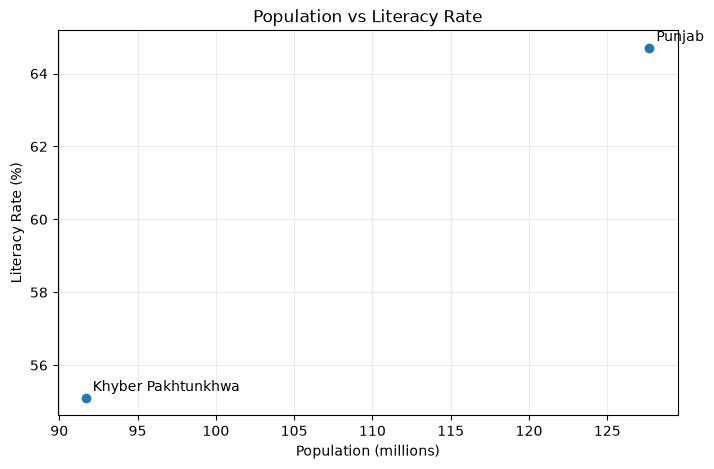

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(
    provinces_encoded["Population"],
    provinces_encoded["Literacy_Rate"]
)

for _, row in provinces_encoded.iterrows():
    plt.annotate(
        row["Province"],
        (row["Population"], row["Literacy_Rate"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Population (millions)")
plt.ylabel("Literacy Rate (%)")
plt.title("Population vs Literacy Rate")
plt.grid(alpha=0.25)
plt.show()

In [5]:
q1 = provinces_encoded["Literacy_Rate"].quantile(0.25)
q3 = provinces_encoded["Literacy_Rate"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

literacy_outliers = provinces_encoded[
    (provinces_encoded["Literacy_Rate"] < lower) |
    (provinces_encoded["Literacy_Rate"] > upper)
]

print("IQR bounds:", lower, "to", upper)
print(literacy_outliers[["Province", "Literacy_Rate"]])

IQR bounds: 50.3 to 69.50000000000001
Empty DataFrame
Columns: [Province, Literacy_Rate]
Index: []
